# ResolveBairro | Previsão de finalização administrativa
Global Solution CitizenTech 2026 - Bug Hunters

## 1. Problema e decisão
Moradores de São Paulo têm dificuldade para compreender a distribuição das solicitações e os tempos de atendimento. Este estudo estima dias corridos até a finalização administrativa de quatro serviços do SP156. Ajuda a estudar o planejamento de equipes, sem prometer prazo, confirmar solução efetiva nem priorizar cidadãos automaticamente. O painel público é o protótipo; o modelo permanece experimental.

## 2. Fonte e variáveis
Fonte: Prefeitura de São Paulo, https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156 . A origem e o download direto constam em fontes_e_metodologia.json. Recorte de aberturas: janeiro a março de 2026. A base analítica recebida foi derivada previamente do CSV público; esta execução verifica seu conteúdo, sem afirmar reprocessamento integral do arquivo bruto.

Alvo: tempo_finalizacao_dias. Preditores: categoria, servico, distrito, mes e dia_semana, disponíveis na abertura. aberto_em é usado na divisão temporal; finalizado_em apenas na construção/verificação do rótulo e disponibilidade temporal. IDs e informações futuras não entram no modelo.

O CSV anexo contém 72.159 registros finalizados com duração válida, extraídos do recorte operacional de 81.350 registros. O painel registra 72.168 finalizações; nove não integram a base de duração válida. A preparação anterior está documentada no repositório e não é reexecutada aqui. Não há nomes, contatos ou endereços completos. Isso produz viés de seleção: chamados ainda abertos não são representados no treinamento. A população-alvo desta avaliação são chamados com duração observada, não todos os chamados futuros.

In [1]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print('Python:',platform.python_version(),'scikit-learn:',sklearn.__version__)
path=Path('base_ml_real.csv')
print('SHA256 base analítica:',hashlib.sha256(path.read_bytes()).hexdigest())
df=pd.read_csv(path)
print('Linhas recebidas:',len(df)); display(df.head()); display(df.dtypes.astype(str).to_frame('tipo'))
display(df.isna().sum().to_frame('ausentes'))


Python: 3.11.0 scikit-learn: 1.9.1
SHA256 base analítica: 60b3c567ca353181f0f348e9f91e67a8a7fae71371a697021bf40722b017bb27


Linhas recebidas: 72159


,id_registro,categoria,servico,distrito,aberto_em,finalizado_em,mes,dia_semana,tempo_finalizacao_dias
0,SP156-2026T1-L193,Buraco na via,Tapa-buraco,SACOMA,2026-01-01,2026-01-08,1,3,7
1,SP156-2026T1-L226,Buraco na via,Tapa-buraco,TATUAPE,2026-01-01,2026-01-07,1,3,6
2,SP156-2026T1-L268,Buraco na via,Tapa-buraco,JARDIM ANGELA,2026-01-01,2026-01-26,1,3,25
3,SP156-2026T1-L270,Buraco na via,Tapa-buraco,VILA MARIANA,2026-01-01,2026-01-07,1,3,6
4,SP156-2026T1-L271,Buraco na via,Tapa-buraco,CAPAO REDONDO,2026-01-01,2026-01-07,1,3,6


,tipo
id_registro,object
categoria,object
servico,object
distrito,object
aberto_em,object
finalizado_em,object
mes,int64
dia_semana,int64
tempo_finalizacao_dias,int64


,ausentes
id_registro,0
categoria,0
servico,0
distrito,108
aberto_em,0
finalizado_em,0
mes,0
dia_semana,0
tempo_finalizacao_dias,0


## 3. Pré-processamento
Datas inválidas e durações negativas são excluídas e contabilizadas. O alvo é recalculado das datas e comparado com o campo recebido. Preditores temporais são recalculados da abertura. Duplicação de chave é bloqueada; não se deduplica por conteúdo sem protocolo oficial. Imputação e codificação são ajustadas dentro de cada treino por Pipeline. Não há remoção arbitrária de durações altas.

Excluídos por datas/duração: 0
Divergências alvo versus datas: 0


,tempo_finalizacao_dias
count,72159.000000
mean,8.635624
std,18.531819
min,0.000000
25%,1.000000
50%,2.000000
75%,5.000000
max,216.000000


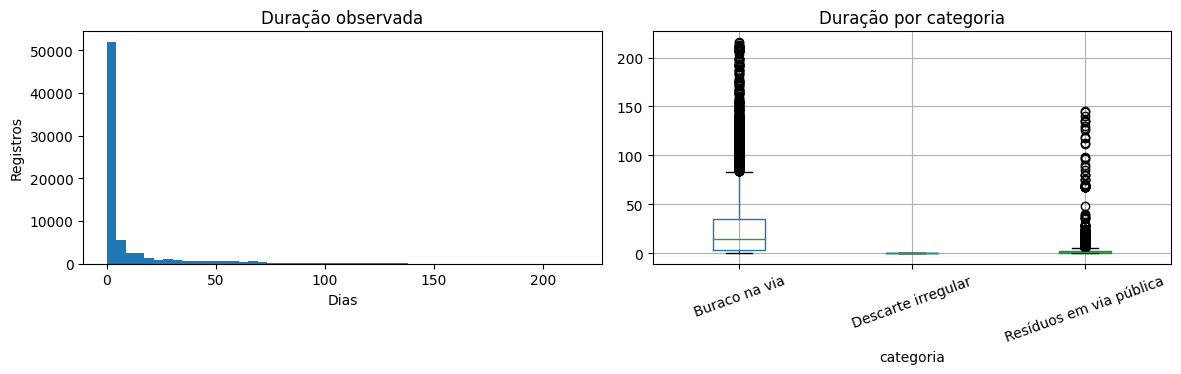

In [2]:
initial=len(df)
for c in ['aberto_em','finalizado_em']:
    df[c]=pd.to_datetime(df[c],errors='coerce')
duration=(df.finalizado_em-df.aberto_em).dt.total_seconds()/86400
valid=df.aberto_em.notna() & df.finalizado_em.notna() & duration.ge(0)
print('Excluídos por datas/duração:',int((~valid).sum()))
print('Divergências alvo versus datas:',int((valid & (pd.to_numeric(df.tempo_finalizacao_dias,errors='coerce')-duration).abs().gt(1e-9)).sum()))
df=df.loc[valid].copy(); df['tempo_finalizacao_dias']=duration.loc[valid]
assert not df.id_registro.duplicated().any(), 'Chave duplicada: revisar antes de treinar'
df['mes']=df.aberto_em.dt.month; df['dia_semana']=df.aberto_em.dt.dayofweek
df=df.sort_values(['aberto_em','id_registro']).reset_index(drop=True)
features=['categoria','servico','distrito','mes','dia_semana']; target='tempo_finalizacao_dias'
display(df[target].describe().to_frame())
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(df[target],bins=50); axes[0].set(title='Duração observada',xlabel='Dias',ylabel='Registros')
df.boxplot(column=target,by='categoria',ax=axes[1],rot=20); axes[1].set_title('Duração por categoria'); plt.suptitle(''); plt.tight_layout(); plt.show()


## 4. Treino, validação e teste temporal
O teste contém aberturas a partir de 13/03/2026, até o fim do trimestre. O treino contém somente aberturas anteriores e rótulos finalizados antes desse corte. Registros anteriores ainda sem rótulo no corte são excluídos do treino e contabilizados.

A validação cruzada usa TimeSeriesSplit sobre dias únicos dentro do treino. Em cada divisão, só entram no ajuste os rótulos conhecidos antes do início da validação. A seleção considera apenas MAE de validação; o teste fica reservado para avaliação final, com rótulos observados no snapshot posterior. Essa avaliação retrospectiva não elimina censura nem viés dos chamados finalizados.

In [3]:
cut=pd.Timestamp('2026-03-13')
train=df[(df.aberto_em<cut)&(df.finalizado_em<cut)].copy()
test=df[df.aberto_em>=cut].copy()
excluded=df[(df.aberto_em<cut)&(df.finalizado_em>=cut)]
print('Treino:',len(train),'Teste:',len(test),'Sem rótulo no corte:',len(excluded))
assert len(train)>100 and len(test)>100
assert train.finalizado_em.max()<test.aberto_em.min()
dates=np.array(sorted(train.aberto_em.unique()))
folds=[]; fold_info=[]
for k,(a,b) in enumerate(TimeSeriesSplit(n_splits=4).split(dates),1):
    start=pd.Timestamp(dates[b[0]])
    tr=train.index[train.aberto_em.isin(dates[a]) & (train.finalizado_em<start)]
    va=train.index[train.aberto_em.isin(dates[b])]
    assert train.loc[tr,'finalizado_em'].max()<train.loc[va,'aberto_em'].min()
    folds.append((tr,va)); fold_info.append({'fold':k,'treino':len(tr),'validacao':len(va),'inicio_validacao':str(start.date())})
display(pd.DataFrame(fold_info))
def make_pipeline(model):
    cat=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))])
    prep=ColumnTransformer([('cat',cat,['categoria','servico','distrito']),('num',SimpleImputer(strategy='median'),['mes','dia_semana'])])
    return Pipeline([('prep',prep),('model',model)])
def models():
    return {'Baseline mediana':make_pipeline(DummyRegressor(strategy='median')),
      'Decision Tree':make_pipeline(DecisionTreeRegressor(max_depth=10,min_samples_leaf=30,random_state=42)),
      'Random Forest':make_pipeline(RandomForestRegressor(n_estimators=100,max_depth=12,min_samples_leaf=20,random_state=42,n_jobs=2))}
def metrics(y,p):
    return {'MAE':mean_absolute_error(y,p),'RMSE':np.sqrt(mean_squared_error(y,p)),'R2':r2_score(y,p)}


Treino: 48330 Teste: 15152 Sem rótulo no corte: 8677


,fold,treino,validacao,inicio_validacao
0,1,9243,10008,2026-01-16
1,2,18733,9765,2026-01-30
2,3,27770,9964,2026-02-13
3,4,38786,7483,2026-02-27


## 5. Modelos e justificativas
Decision Tree permite relações não lineares e interações entre serviço, distrito e calendário. Random Forest combina árvores para reduzir variância. Profundidade e tamanho mínimo de folha limitam sobreajuste; os parâmetros foram fixados antes do teste. Baseline pela mediana minimiza erro absoluto constante e estabelece uma referência necessária. Não foi feita busca extensiva de hiperparâmetros.

In [4]:
cv=[]
for name,model in models().items():
    for k,(tr,va) in enumerate(folds,1):
        model.fit(train.loc[tr,features],train.loc[tr,target])
        p=model.predict(train.loc[va,features])
        cv.append({'modelo':name,'fold':k,**metrics(train.loc[va,target],p)})
cv=pd.DataFrame(cv); display(cv)
summary=cv.groupby('modelo')[['MAE','RMSE','R2']].mean().sort_values('MAE')
display(summary)
selected=summary.index[0]
print('Selecionado apenas por CV MAE:',selected)


,modelo,fold,MAE,RMSE,R2
0,Baseline mediana,1,3.558653,7.538808,-0.189601
1,Baseline mediana,2,3.168868,6.234338,-0.242973
2,Baseline mediana,3,1.883982,3.557606,-0.193332
3,Baseline mediana,4,1.104504,1.855209,-0.079938
4,Decision Tree,1,3.368730,7.052229,-0.040995
5,Decision Tree,2,2.848499,5.146026,0.153114
6,Decision Tree,3,1.844646,3.159266,0.058938
7,Decision Tree,4,1.643845,2.326176,-0.697846
8,Random Forest,1,3.343315,7.041765,-0.037908
9,Random Forest,2,2.827122,5.127929,0.159060


,MAE,RMSE,R2
modelo,,,
Random Forest,2.403179,4.395651,-0.107158
Decision Tree,2.426430,4.420924,-0.131697
Baseline mediana,2.429002,4.796491,-0.176461


Selecionado apenas por CV MAE: Random Forest


## 6. Avaliação final reservada
MAE mede erro absoluto médio em dias; RMSE penaliza erros grandes. R² negativo significa desempenho inferior à previsão constante pela média dos valores reais desse teste em erro quadrático. Isso não determina, sozinho, a comparação em MAE com baseline treinado, que é mostrada separadamente. Avaliamos todos os candidatos para transparência, sem trocar o vencedor após olhar o teste.

,modelo,CV_MAE,CV_RMSE,CV_R2,teste_MAE,teste_RMSE,teste_R2
0,Baseline mediana,2.429002,4.796491,-0.176461,5.752310,14.820901,-0.148074
1,Decision Tree,2.426430,4.420924,-0.131697,5.475676,14.385284,-0.081577
2,Random Forest,2.403179,4.395651,-0.107158,5.468656,14.385082,-0.081547


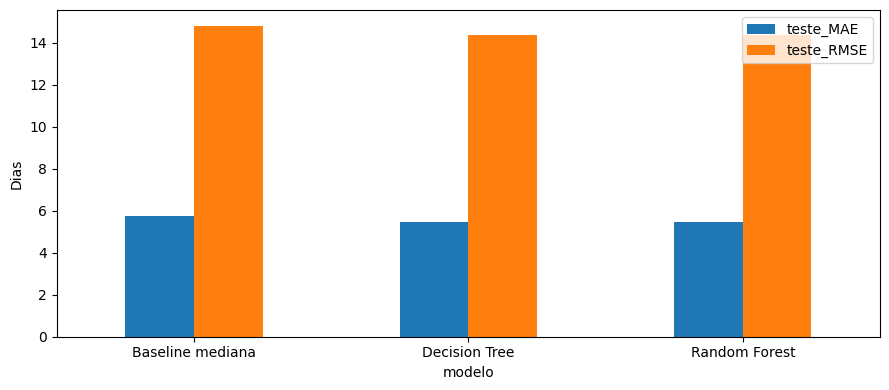

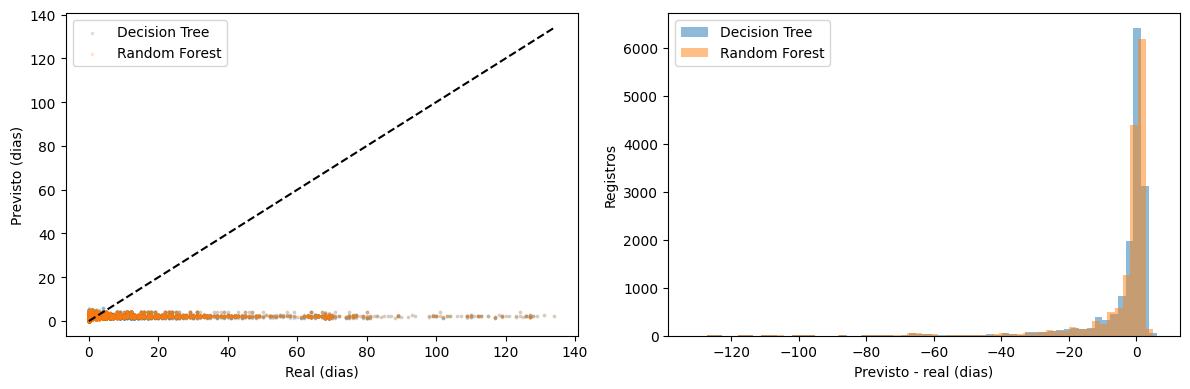

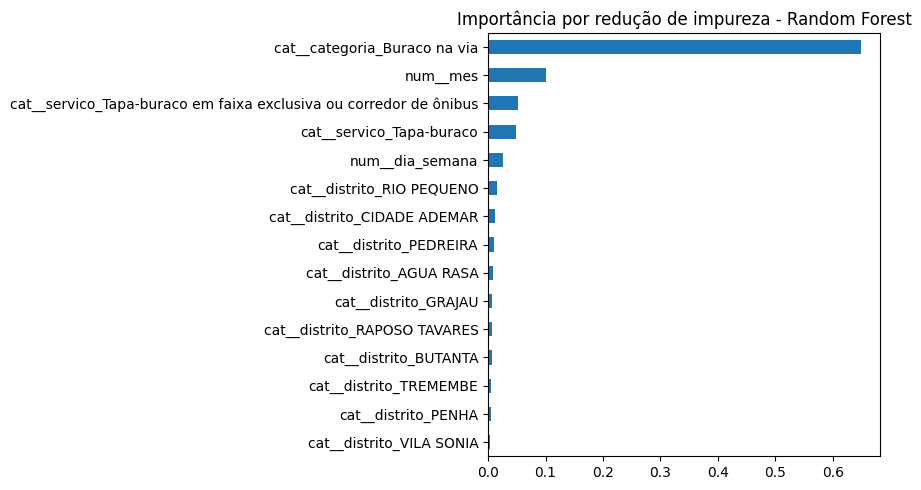

In [5]:
fitted={}; rows=[]; predictions=test[['id_registro','aberto_em','categoria','distrito',target]].copy()
for name,model in models().items():
    model.fit(train[features],train[target]); fitted[name]=model
    p=model.predict(test[features]); predictions[name]=p
    rows.append({'modelo':name,'CV_MAE':summary.loc[name,'MAE'],'CV_RMSE':summary.loc[name,'RMSE'],'CV_R2':summary.loc[name,'R2'],**{'teste_'+k:v for k,v in metrics(test[target],p).items()}})
results=pd.DataFrame(rows); display(results.round(6))
results.to_csv('resultados_modelos.csv',index=False); cv.to_csv('validacao_folds.csv',index=False)
predictions.to_csv('predicoes_teste.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4)); results.set_index('modelo')[['teste_MAE','teste_RMSE']].plot.bar(ax=ax); ax.set_ylabel('Dias'); ax.tick_params(axis='x',rotation=0); plt.tight_layout(); plt.savefig('comparacao_modelos.png',dpi=160); plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name in ['Decision Tree','Random Forest']:
    axes[0].scatter(test[target],predictions[name],s=3,alpha=.15,label=name)
    axes[1].hist(predictions[name]-test[target],bins=60,alpha=.5,label=name)
axes[0].plot([0,test[target].max()],[0,test[target].max()],'k--'); axes[0].set(xlabel='Real (dias)',ylabel='Previsto (dias)')
axes[1].set(xlabel='Previsto - real (dias)',ylabel='Registros')
for ax in axes: ax.legend()
plt.tight_layout(); plt.savefig('erros_teste.png',dpi=160); plt.show()
rf=fitted['Random Forest']; names=rf.named_steps['prep'].get_feature_names_out()
importance=pd.Series(rf.named_steps['model'].feature_importances_,index=names).nlargest(15)
importance.sort_values().plot.barh(figsize=(9,5),title='Importância por redução de impureza - Random Forest'); plt.tight_layout(); plt.savefig('importancia.png',dpi=160); plt.show()


## 7. Erros por grupo, conclusão e limitações
Importância por impureza não demonstra causalidade e pode favorecer variáveis com muitas categorias. Categoria e serviço carregam informação redundante. O mês varia pouco neste trimestre. Ausência de população por distrito impede medir cobertura equitativa por habitante. Pessoas com pouco acesso digital podem gerar menos registros sem ter menos necessidade.

As métricas por distrito e categoria abaixo ajudam a identificar grupos com erros maiores, mas amostras pequenas exigem cautela. Não se usam dados sensíveis para decidir prioridades. Recomenda-se ampliar o histórico, estudar censura dos chamados em aberto e testar em outro trimestre antes de qualquer uso operacional.

In [6]:
chosen=results.set_index('modelo').loc[selected]
print(f'Modelo selecionado por validação: {selected}. MAE final: {chosen.teste_MAE:.3f} dias; RMSE: {chosen.teste_RMSE:.3f}; R²: {chosen.teste_R2:.3f}.')
print('Melhor MAE observado no teste (descritivo; não altera seleção):',results.loc[results.teste_MAE.idxmin(),'modelo'])
for group in ['categoria','distrito']:
    errs=predictions.assign(erro_abs=(predictions[selected]-predictions[target]).abs()).groupby(group).agg(n=(target,'size'),MAE=('erro_abs','mean')).sort_values('MAE',ascending=False)
    errs.to_csv('erros_por_'+group+'.csv'); display(errs.head(15))
conclusion={'selecionado_por_cv':selected,'treino':len(train),'teste':len(test),'excluidos_sem_rotulo_corte':len(excluded),'metricas':results.to_dict(orient='records'),'base_sha256':hashlib.sha256(path.read_bytes()).hexdigest()}
Path('resumo_execucao.json').write_text(json.dumps(conclusion,ensure_ascii=False,indent=2),encoding='utf-8')
print('Decisão: manter modelo como estudo acadêmico, sem promessas de prazo ou priorização automática. Benefícios sociais ainda são hipóteses a validar em piloto com cidadãos e gestores.')


Modelo selecionado por validação: Random Forest. MAE final: 5.469 dias; RMSE: 14.385; R²: -0.082.
Melhor MAE observado no teste (descritivo; não altera seleção): Random Forest


,n,MAE
categoria,,
Buraco na via,4735,14.276644
Resíduos em via pública,9905,1.538878
Descarte irregular,512,0.036292


,n,MAE
distrito,,
SE,40,17.411278
BRAS,50,16.006462
PARELHEIROS,131,13.540547
PINHEIROS,112,12.527056
ALTO DE PINHEIROS,36,11.927957
MORUMBI,106,11.187517
SAO LUCAS,110,11.045655
MOOCA,77,10.724699
BOM RETIRO,30,10.655021


Decisão: manter modelo como estudo acadêmico, sem promessas de prazo ou priorização automática. Benefícios sociais ainda são hipóteses a validar em piloto com cidadãos e gestores.
